# Notebook 1 · Rotina híbrida consolidada e conferência da cozinha · v08

**CIV2155 · FNDE Tipo 2 · arquitetura ARQ-DTV R03.**

Este é o ponto de entrada consolidado desta revisão. As versões v03–v07 permanecem como histórico; suas células não são acumuladas novamente aqui. A rotina recebe o IFC e o GUID da cozinha, reexecuta os recortes e interfaces, organiza as relações e depois compara a saída com as pranchas oficiais.

**Objetivo da conferência:** verificar quais portas/janelas principais foram associadas corretamente à cozinha, quais associações vizinhas são indevidas e quais esquadrias ficaram de fora. Componentes sem preenchimento declarado e alvenarias internas são examinados separadamente.

**Resultado a verificar:** frente à consulta antiga v03, recuperar quatro janelas e eliminar duas associações com a copa. A comparação com IFC2SB parcial v04 permite verificar se o híbrido realmente acrescenta novos acertos ou apenas mantém os acertos e organiza melhor as evidências.

**Alcance:** um perfil de entrada, a cozinha FNDE R03. Ainda não é uma rotina validada para todos os 41 ambientes. A referência documental foi lida com assistência de IA, não em avaliação cega por especialista.

## Fontes e contribuição efetivamente utilizada

| Fonte | Papel nesta revisão |
|---|---|
| [Bonduel et al. (2018), IFCtoLBD](https://ceur-ws.org/Vol-2159/04paper.pdf) | Conversão 2.49.0 e correção textual anteriores reutilizadas por hash, com os 41 ambientes e suas propriedades. Java não é reexecutado. |
| [Fichter et al. (2021), IFC2SB](https://doi.org/10.26868/25222708.2021.30156) | Adaptação parcial de recortes e ancestralidade reexecutada sobre o IFC original da cozinha. |
| [Kiavarz et al. (2023)](https://doi.org/10.3390/buildings13020350) | Interfaces por projeção/interseção e sondas, com as adaptações dos §§4.2.2–4.4 explicitadas nos módulos anteriores. |
| [Krijnen et al. (2020)](https://doi.org/10.46421/2706-6568.37.2020.paper008) | Avaliações CGAL anteriores, verificadas por hash e mantidas como sinais globais das paredes. Motor não reexecutado. |
| [Lilis et al. (2026)](https://doi.org/10.1016/j.autcon.2026.106840) | Comparação opcional de operadores parciais. Desativada no núcleo desta execução; controles repetidos. Sem alpha wrap. |
| [Zhang et al. (2018), BimSPARQL/GEOM](https://doi.org/10.3233/SW-180297) | Coordenadas e geometrias no RDF, preservadas no grafo principal. |
| [FNDE, Projeto Tipo 2 R03](https://www.gov.br/fnde/pt-br/acesso-a-informacao/acoes-e-programas/programas/proinfancia/projetos-arquitetonicos-para-construcao/projeto-tipo-2) | Pranchas 02, 24, 25 e 26 como referência documental. |

A orquestração, o inventário de cobertura, as regras novas de candidatos internos/componentes, a ligação por GUID e a avaliação são rotinas específicas deste estudo. Não são apresentadas como programa completo de nenhum desses autores. As fontes técnicas são [IfcOpenShell](https://docs.ifcopenshell.org/ifcopenshell-python/geometry_processing.html), [OCP](https://github.com/CadQuery/OCP), [Shapely](https://shapely.readthedocs.io/en/stable/reference/shapely.intersection.html) e [RDFLib](https://rdflib.readthedocs.io/en/stable/intro_to_graphs/).

## 1. Preparar as bibliotecas e o ponto de trabalho

O notebook baixa código e entradas de uma revisão fixa. Para usar arquivos locais, as variáveis opcionais indicadas na próxima célula substituem apenas o download; todos os hashes continuam obrigatórios. A execução registrada usa um novo kernel, sem aproveitar variáveis de versões anteriores.

In [1]:
from pathlib import Path
import os,sys,json,hashlib,zipfile,shutil,subprocess,importlib.util
from urllib.request import urlretrieve
dependencias={'numpy':'numpy','ifcopenshell':'ifcopenshell==0.8.4','OCP':'cadquery-ocp==7.8.1.1.post1','shapely':'shapely==2.2.0','rdflib':'rdflib==7.1.4','matplotlib':'matplotlib==3.10.7'}
faltantes=[p for m,p in dependencias.items() if importlib.util.find_spec(m) is None]
if faltantes:subprocess.check_call([sys.executable,'-m','pip','install',*faltantes])
import numpy,ifcopenshell,OCP,shapely,rdflib,matplotlib
RAIZ=Path(os.environ.get('CIV2155_CONSOL_RAIZ','CIV2155_Notebook1_v08')).resolve()
RAIZ.mkdir(parents=True,exist_ok=True)
sha=lambda p:hashlib.sha256(Path(p).read_bytes()).hexdigest()
print('Python',sys.version.split()[0],'IfcOpenShell',ifcopenshell.version,'OCP',OCP.__version__,'Shapely',shapely.__version__)


Python 3.12.14 IfcOpenShell 0.8.4 OCP 7.8.1.1 Shapely 2.2.0


## 2. Importar o IFC, o grafo principal anterior e as entradas fixadas

O IFC é o original ARQ-DTV R03. O grafo completo anterior tem 117.591 triplas e contém a conversão semântica, geometrias e diagnósticos dos 41 ambientes. Ele será preservado e receberá o complemento atual. A reutilização por hash é explícita: não estamos anunciando uma nova execução da conversão ou dos testes globais da v03.

O pacote menor inclui código, avaliações CGAL, triagem anterior de Lilis, fontes, pranchas e referência documental. A função de previsão só recebe a subpasta `entrada`; a referência é usada posteriormente na avaliação. As pranchas originais do FNDE não são alteradas.

In [2]:
SNAPSHOT='8301fc9238e0e15a6874b7dc8f4d5882e8695cef'
BASE='https://raw.githubusercontent.com/prcgui/bim-ontology-CIV2155/'+SNAPSHOT+'/'
PACOTE=RAIZ/'Pacote_Consolidacao_v08.zip'
local=os.environ.get('CIV2155_CONSOL_PACOTE')
if local:shutil.copy2(local,PACOTE)
else:urlretrieve(BASE+'resultados/consolidacao_hibrido_v01/Pacote_Consolidacao_v08.zip',PACOTE)
assert sha(PACOTE)=='b06d5c3dd942991250f03c25cd7fa4a7ef9e7910878c448a78e18237670ba8df'
with zipfile.ZipFile(PACOTE) as z:z.extractall(RAIZ)
PACOTE_N1=RAIZ/'CIV2155_Notebook1_v03_Resultados.zip'
local=os.environ.get('CIV2155_CONSOL_BASE')
if local:shutil.copy2(local,PACOTE_N1)
else:urlretrieve(BASE+'resultados/notebook1_v03/CIV2155_Notebook1_v03_Resultados.zip',PACOTE_N1)
assert sha(PACOTE_N1)=='19def379f930bcc38cd849c348695d1ffbe4c77be643196556564fae06d73322'
IFC=RAIZ/'TIPO2-ARQ-DTV_R03.ifc'
local=os.environ.get('CIV2155_CONSOL_IFC')
if local:shutil.copy2(local,IFC)
else:
    compacto=RAIZ/'Arquitetura_Original.zip'
    urlretrieve(BASE+'dados/fnde/arquitetura/TIPO2-ARQ-DTV_R03.ifc.zip',compacto)
    with zipfile.ZipFile(compacto) as z:IFC.write_bytes(z.read(IFC.name))
IFC_SHA='0975bf1394694eff8746e5e49232bdf950c36c37c858edb715c9e7bc8f65603a'
assert sha(IFC)==IFC_SHA
sys.path.insert(0,str(RAIZ/'codigo'))
ENTRADA=RAIZ/'entrada';REFERENCIAS=RAIZ/'referencias'
SAIDA=RAIZ/'resultados';SAIDA.mkdir(exist_ok=True)
AMBIENTE='3UFjAT4k55zg_Pqo6VMw5l'
modelo=ifcopenshell.open(str(IFC))
print('IFC:',len(modelo.by_type('IfcSpace')),'ambientes;',len(modelo.by_type('IfcOpeningElement')),'aberturas;',len(modelo.by_type('IfcDoor')),'portas;',len(modelo.by_type('IfcWindow')),'entidades IfcWindow')
print('Entradas verificadas por SHA-256. Cozinha:',modelo.by_guid(AMBIENTE).LongName)


IFC: 41 ambientes; 184 aberturas; 53 portas; 39 entidades IfcWindow
Entradas verificadas por SHA-256. Cozinha: COZINHA


## 3. Conferir os operadores antes da aplicação

São repetidos 17 controles da adaptação IFC2SB, 17 de Kiavarz e 20 de Lilis. A referência C++ dos controles IFC2SB é o resultado arquivado de corpos originais compilados anteriormente; C++ não é recompilado nesta célula. Os casos analíticos verificam áreas, planos, furos, rotação, translação, ancestralidade e aberturas em paredes compartilhadas.

Cinco controles adicionais verificam as métricas: acerto, associação indevida, omissão, exclusão correta, denominador vazio e registro de previsão fora da referência. Um caso documental indeterminado deve ficar fora da contagem de acertos. Esses controles são específicos da avaliação deste estudo.

In [3]:
from testar_adaptacao import run as testar_ifc2sb
from testar_faces import run as testar_kiavarz
from controles_lilis import run as testar_lilis
from conferir_documentos import controles_metricas
controle_dir=SAIDA/'controles'
c1=testar_ifc2sb(RAIZ/'codigo/referencia_cpp/Resultado_CPP.json',controle_dir/'ifc2sb')
c2=testar_kiavarz(controle_dir/'kiavarz')
c3=testar_lilis(controle_dir/'lilis')
c4=controles_metricas()
assert [c1['aprovados'],c2['aprovados'],c3['aprovados'],c4['aprovados']]==[17,17,20,5]
print('59 controles aprovados. Isso não equivale a validar a arquitetura completa.')


CONTROLES 17 / 17
CONTROLES 17 / 17
Controles Lilis: 20 aprovados
59 controles aprovados. Isso não equivale a validar a arquitetura completa.


## 4. Executar a rotina consolidada

Uma única chamada coordena estas etapas:

1. **IFC2SB parcial:** ler o IFC, preparar o volume da cozinha, examinar as 457 paredes e produzir os recortes com ancestralidade, sem regravar o IFC.
2. **Kiavarz adaptado:** construir as interfaces locais da cozinha e cruzá-las com os recortes. Uma porta não é associada apenas por compartilhar a parede.
3. **Krijnen/CGAL:** vincular os resultados anteriores verificados. Um sinal da parede inteira não se transforma automaticamente em conflito em toda abertura.
4. **Cobertura:** inventariar todas as 184 aberturas e todas as 92 entidades IfcDoor/IfcWindow, incluindo objetos sem `IfcRelFillsElement`. A caixa é somente pré-filtro.
5. **Saídas distintas:** esquadrias com recorte local; outros preenchimentos; elementos internos candidatos; componentes sem preenchimento declarado associados por proximidade.

As duas últimas regras são extensões deste estudo. Os internos têm vértices IN/ON, com ao menos um IN, usando tolerância de 10⁻⁵ m; isso não prova contenção integral de formas côncavas. Para componentes sem FillsVoids, a distância entre caixas é até 0,25 m e o centro deve ficar nas duas direções do plano da esquadria com margem de 0,02 m. Esses vínculos são candidatos, não novas relações declaradas IFC.

Lilis permanece disponível com `comparar_lilis=True`; o padrão é `False`. A comparação parcial não altera as decisões do núcleo e não equivale ao fluxo completo dos autores. O perfil aceita somente o IFC e a cozinha desta revisão; recusa outros GUIDs para evitar reutilização silenciosa de avaliações incompatíveis.

In [4]:
from rotina_hibrida import executar_ambiente
resultado=executar_ambiente(IFC,AMBIENTE,ENTRADA,SAIDA,comparar_lilis=False)
print(json.dumps(resultado['resumo'],ensure_ascii=False,indent=2))
assert resultado['ifc_original_preservado']
assert resultado['resumo']=={'interfaces':14,'paredes_com_interface':10,'esquadrias_distintas':9,'outros_preenchimentos':1,'elementos_internos_candidatos':10,'componentes_sem_FillsVoids':3}
print('A referência documental ainda não foi usada na avaliação dessas previsões.')


ETAPA 1: reexecutar recortes IFC2SB no IFC original.


W01 0XAHc8zyr1YuL0AWxiP2D2 aberturas 5 faces 104 contato_bruto 10.012775731856873


W02 3lgLMxPtX22hHa1J_NWBcS aberturas 1 faces 18 contato_bruto 0.0


W03

 2gY30MgeHFYR7UxJlNnU9q aberturas 0 faces 0 contato_bruto 18.600002762841427


...

{
  "paredes_candidatas": 34,
  "interfaces": 14,
  "interfaces_qualificadas": 14,
  "paredes_com_interface": 10,
  "recortes_aberturas": 11,
  "aberturas_associadas": 10,
  "aberturas_examinadas": 24,
  "interfaces_sensibilidade_sondas": 0,
  "recortes_com_problema_parental": 0,
  "faces_nao_cobertas": 11
}


{
  "triplas_entrada": 1946,
  "triplas_saida": 2559,
  "interfaces": 14,
  "interfaces_qualificadas": 14,
  "recortes_aberturas": 11,
  "aberturas_associadas": 10,
  "classes_dos_10_preenchimentos": {
    "IfcDoor": 3,
    "IfcWindow": 6,
    "IfcWall": 1
  },
  "avaliacoes_aberturas": 24,
  "linhas_consulta": 18,
  "sha256_rdf_entrada": "0a68c9ce3864e9f9345d1497b07030966de51b6a6048f7883057c9ddc6a44fcb",
  "sha256_rdf_saida": "af131d8b300b34f8e80d6f14ae7125e134d39fb43efc36c46a6d88674b2269b5",
  "roundtrip_e_preservacao": true,
  "novas_adjacencias_bot_certificadas": 0,
  "limite": "Relações qualificadas geometricamente no recorte; significado e completude arquitetônica permanecem sem validação independente."
}
ETAPA 3: inventário independente de todas as aberturas e esquadrias.


{"aberturas_ifc": 184, "aberturas_proximas": 26, "portas_e_janelas_ifc": 92, "portas_e_janelas_proximas": 18}


ROTINA CONCLUÍDA: {"interfaces": 14, "paredes_com_interface": 10, "esquadrias_distintas": 9, "outros_preenchimentos": 1, "elementos_internos_candidatos": 10, "componentes_sem_FillsVoids": 3}


{
  "interfaces": 14,
  "paredes_com_interface": 10,
  "esquadrias_distintas": 9,
  "outros_preenchimentos": 1,
  "elementos_internos_candidatos": 10,
  "componentes_sem_FillsVoids": 3
}
A referência documental ainda não foi usada na avaliação dessas previsões.


## 5. Conferir a cozinha nas pranchas oficiais

A referência está no arquivo `Referencia_Documental_Cozinha_R03.json`, com GUID, tipo, posição, ambiente vizinho, prancha/vista e justificativa por caso. Foi construída por leitura visual das pranchas **02/36, 24/36, 25/36 e 26/36, R03, JAN/2025**. Os hashes dos PDFs e do pacote de origem são registrados. A correspondência ao IFC usa tipo, posição e vizinhança; a saída prevista não define o que conta como acerto.

Há oito esquadrias principais com referência positiva: PA1, PA2, PM2, uma JA-06, uma JA-02, uma JA-03 e duas JA-10. Seis objetos de ambientes vizinhos são referências negativas. A JA-09 fica **indeterminada**: a planta geral 02 a mostra no lado leste da cozinha, mas a planta ampliada 24 e a vista 02 da prancha 25 não a representam. O IFC contém a janela nesse ponto.

Comparamos a mesma relação em três procedimentos: a consulta antiga v03 que percorre a parede e suas aberturas; o IFC2SB parcial v04; e o híbrido consolidado v08. Os resultados indeterminados são publicados e excluídos das métricas. Componentes V02 e alvenarias internas têm avaliação separada.

**Limite:** conferência documental assistida por IA, não cega nem revista por especialista independente. A amostra não certifica os 41 cômodos. Não foi construída referência exaustiva para as 14 superfícies 3D, lajes, coberturas, mobiliário ou instalações.

**Como interpretar a linha v03:** a consulta antiga lista cadeias por parede e já advertia que isso não prova pertencimento da esquadria ao cômodo. Nesta comparação, sua listagem é avaliada como hipótese exploratória para essa pergunta. Os dois casos indevidos e as quatro omissões descrevem o que ocorre ao usar a listagem dessa forma; não são uma alegação de que a v03 já certificava atribuição arquitetônica. O ganho frente à v04 é de organização/rastreabilidade, sem novos acertos demonstrados nas esquadrias.

In [5]:
from conferir_documentos import run as conferir
conferencia=conferir(SAIDA/'Resultado_Consolidado_Cozinha_v08.json',REFERENCIAS/'Referencia_Documental_Cozinha_R03.json',ENTRADA,SAIDA/'conferencia')
for m in conferencia['metricas']:
    print(m['procedimento'],'| corretas:',m['TP'],'| indevidas:',m['FP'],'| omissões:',m['FN'],'| exclusões corretas:',m['TN'])
assert [(m['TP'],m['FP'],m['FN']) for m in conferencia['metricas']]==[(4,2,4),(8,0,0),(8,0,0)]
assert len(conferencia['casos_documentais_indeterminados'])==1
print('Conflito documental preservado:',conferencia['casos_documentais_indeterminados'][0]['nome'])
print('Ganho de acerto vs IFC2SB v04:',conferencia['diferencas_esquadrias_vs_IFC2SB_v04'])


[
  {
    "procedimento": "Consulta_N1_v03_parede_abertura",
    "TP": 4,
    "FP": 2,
    "FN": 4,
    "TN": 4,
    "precisao_no_recorte": 0.6666666666666666,
    "sensibilidade_no_recorte": 0.5,
    "casos_determinados": 14,
    "indeterminados": 1,
    "previsoes_fora_da_referencia": []
  },
  {
    "procedimento": "IFC2SB_parcial_v04",
    "TP": 8,
    "FP": 0,
    "FN": 0,
    "TN": 6,
    "precisao_no_recorte": 1.0,
    "sensibilidade_no_recorte": 1.0,
    "casos_determinados": 14,
    "indeterminados": 1,
    "previsoes_fora_da_referencia": []
  },
  {
    "procedimento": "Hibrido_consolidado_v08",
    "TP": 8,
    "FP": 0,
    "FN": 0,
    "TN": 6,
    "precisao_no_recorte": 1.0,
    "sensibilidade_no_recorte": 1.0,
    "casos_determinados": 14,
    "indeterminados": 1,
    "previsoes_fora_da_referencia": []
  }
]
Consulta_N1_v03_parede_abertura | corretas: 4 | indevidas: 2 | omissões: 4 | exclusões corretas: 4
IFC2SB_parcial_v04 | corretas: 8 | indevidas: 0 | omissões: 0 | exc

## 6. Integrar ao grafo completo do Notebook 1

Esta etapa liga as identidades do piloto às identidades já existentes na conversão IFCtoLBD. A correspondência exige `GlobalId` único no mesmo IFC, com SHA-256 verificado. As coordenadas, interfaces e evidências permanecem consultáveis.

O grafo completo anterior de 117.591 triplas é preservado byte a byte como prefixo do novo Turtle. O complemento é acrescentado, a união é reaberta e a consulta atual é executada no arquivo final. O arquivo grande é entregue compactado, além do complemento menor em Turtle.

**Consulta atual:** cozinha → `con:esquadriaAssociada` → elemento → `con:aberturaFonte`. Isso evita voltar à consulta que atribui todas as portas/janelas de uma parede ao cômodo. As relações históricas e os diagnósticos permanecem; as novas propriedades têm significado e limites em `Vocabulario_Consolidado.ttl`.

A JA-09 conserva a associação geométrica, acompanhada da situação documental indeterminada. `IfcWall` AL25 permanece outro preenchimento; não é renomeado como esquadria. Dez internos e três componentes sem FillsVoids são mantidos como candidatos.

In [6]:
from integrar_grafo_principal import run as integrar
integracao=integrar(PACOTE_N1,SAIDA/'Complemento_Hibrido_Consolidado_v08.ttl',SAIDA/'conferencia/Conferencia_Documental_Cozinha_v08.json',SAIDA/'Resultado_Consolidado_Cozinha_v08.json',SAIDA/'rdf_principal')
assert integracao['consulta_reaberta_aprovada'] and integracao['esquadrias_consulta_distintas']==9
assert integracao['triplas_base_historica']==117591
print('Consulta executada sobre a união salva. Base anterior preservada:',integracao['sha256_prefixo_base'])


Reabrindo o grafo completo do Notebook 1 para consulta...


{
  "triplas_base_historica": 117591,
  "triplas_uniao_atual": 120191,
  "triplas_complemento": 2649,
  "produtos_mapeados_por_GUID": 75,
  "esquadrias_consulta_distintas": 9,
  "linhas_consulta_com_labels": 9,
  "prefixo_base_preservado_bytes": 186157711,
  "sha256_prefixo_base": "7694e6bc327485ae320de14e51cc3229f43b0574e922a84454129428387af9db",
  "sha256_saida": "caa11e9c3e0e196df14a3a3265b35498e6ad6b9b46d5df569cb9602887f5db14",
  "consulta_reaberta_aprovada": true,
  "limite": "Preserva o grafo anterior e seus diagnósticos; a consulta atual usa con:esquadriaAssociada, sem transitividade via parede."
}
Consulta executada sobre a união salva. Base anterior preservada: 7694e6bc327485ae320de14e51cc3229f43b0574e922a84454129428387af9db


## 7. Visualizar acertos, associações indevidas e omissões

As figuras abaixo usam os resultados e a referência caso a caso. O mapa deriva do IFC e mostra o contorno da cozinha no corte Z = 1,20 m, com centros dos objetos projetados em XY; não deve ser confundido com a prancha original. O relatório traz os casos individuais, justificativas, imagens documentais e tabelas completas.

Os dois objetos associados indevidamente pela consulta v03 são uma PA2 e uma JA-06 da copa, na mesma parede longa do lado leste. As quatro janelas recuperadas ficam no lado oeste: JA-02, JA-03 e duas JA-10. O conflito JA-09 aparece em categoria própria.

Figuras e relatório produzidos.


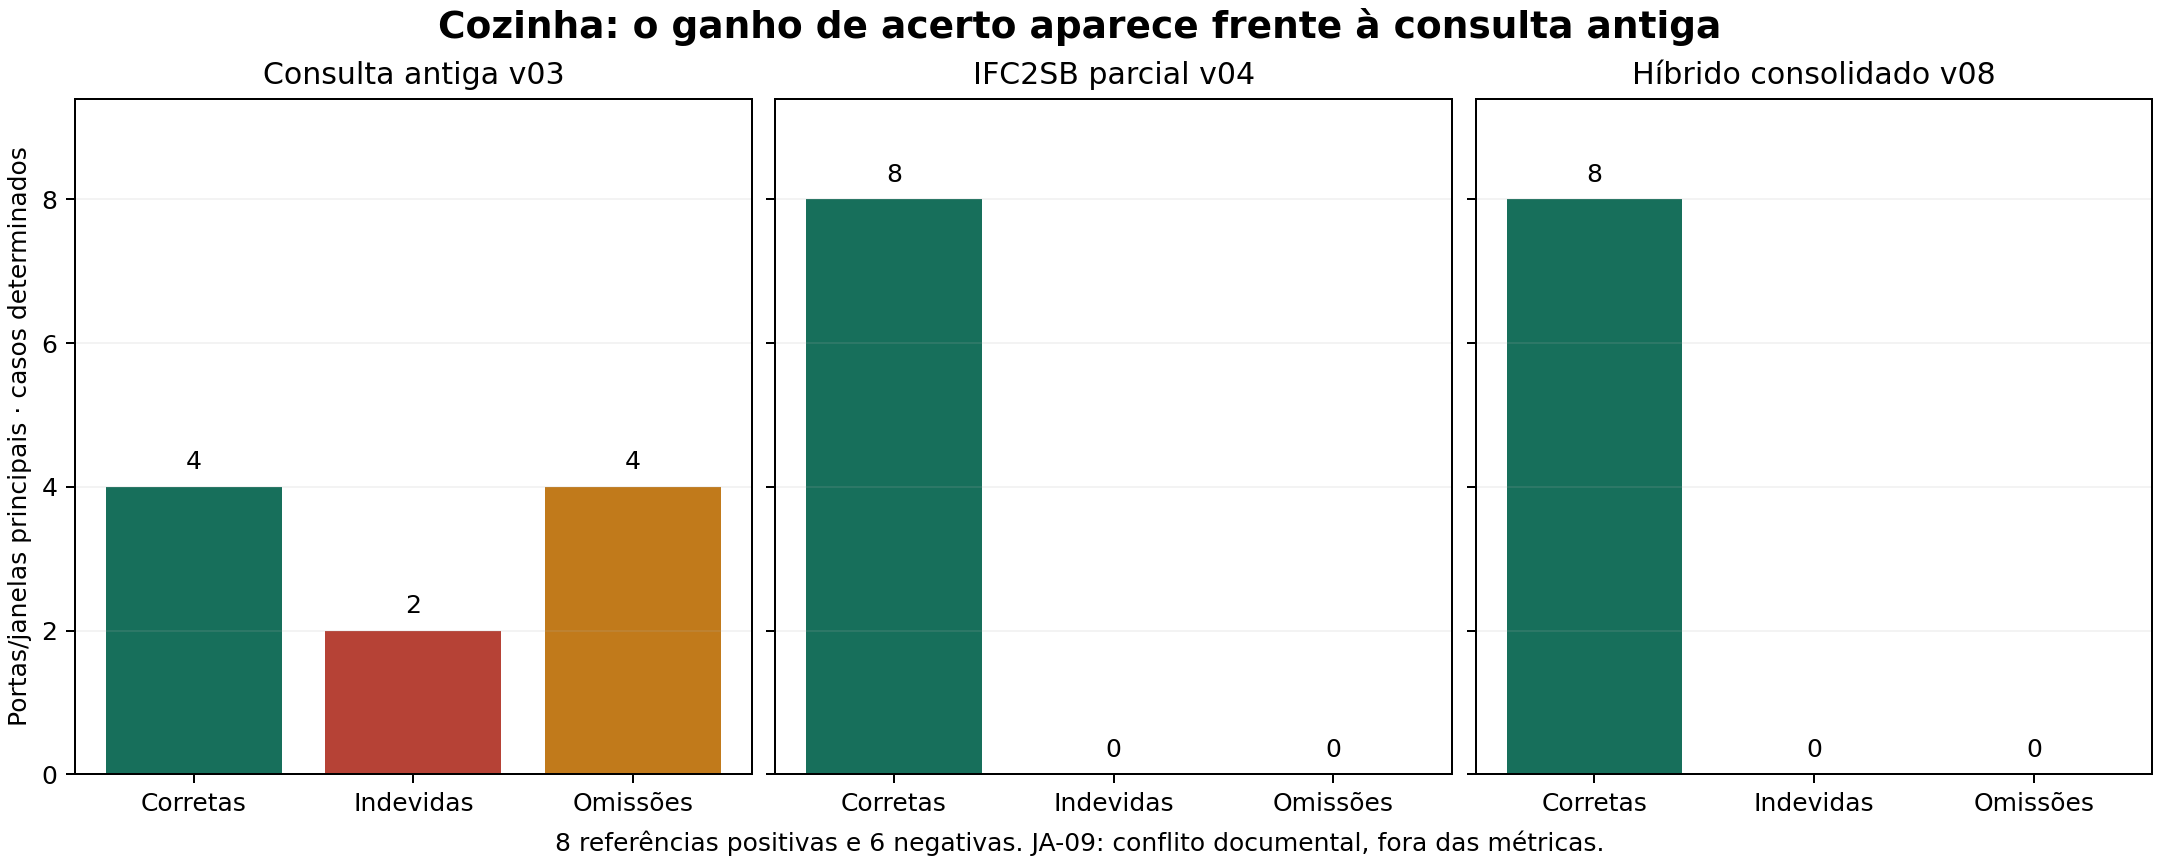

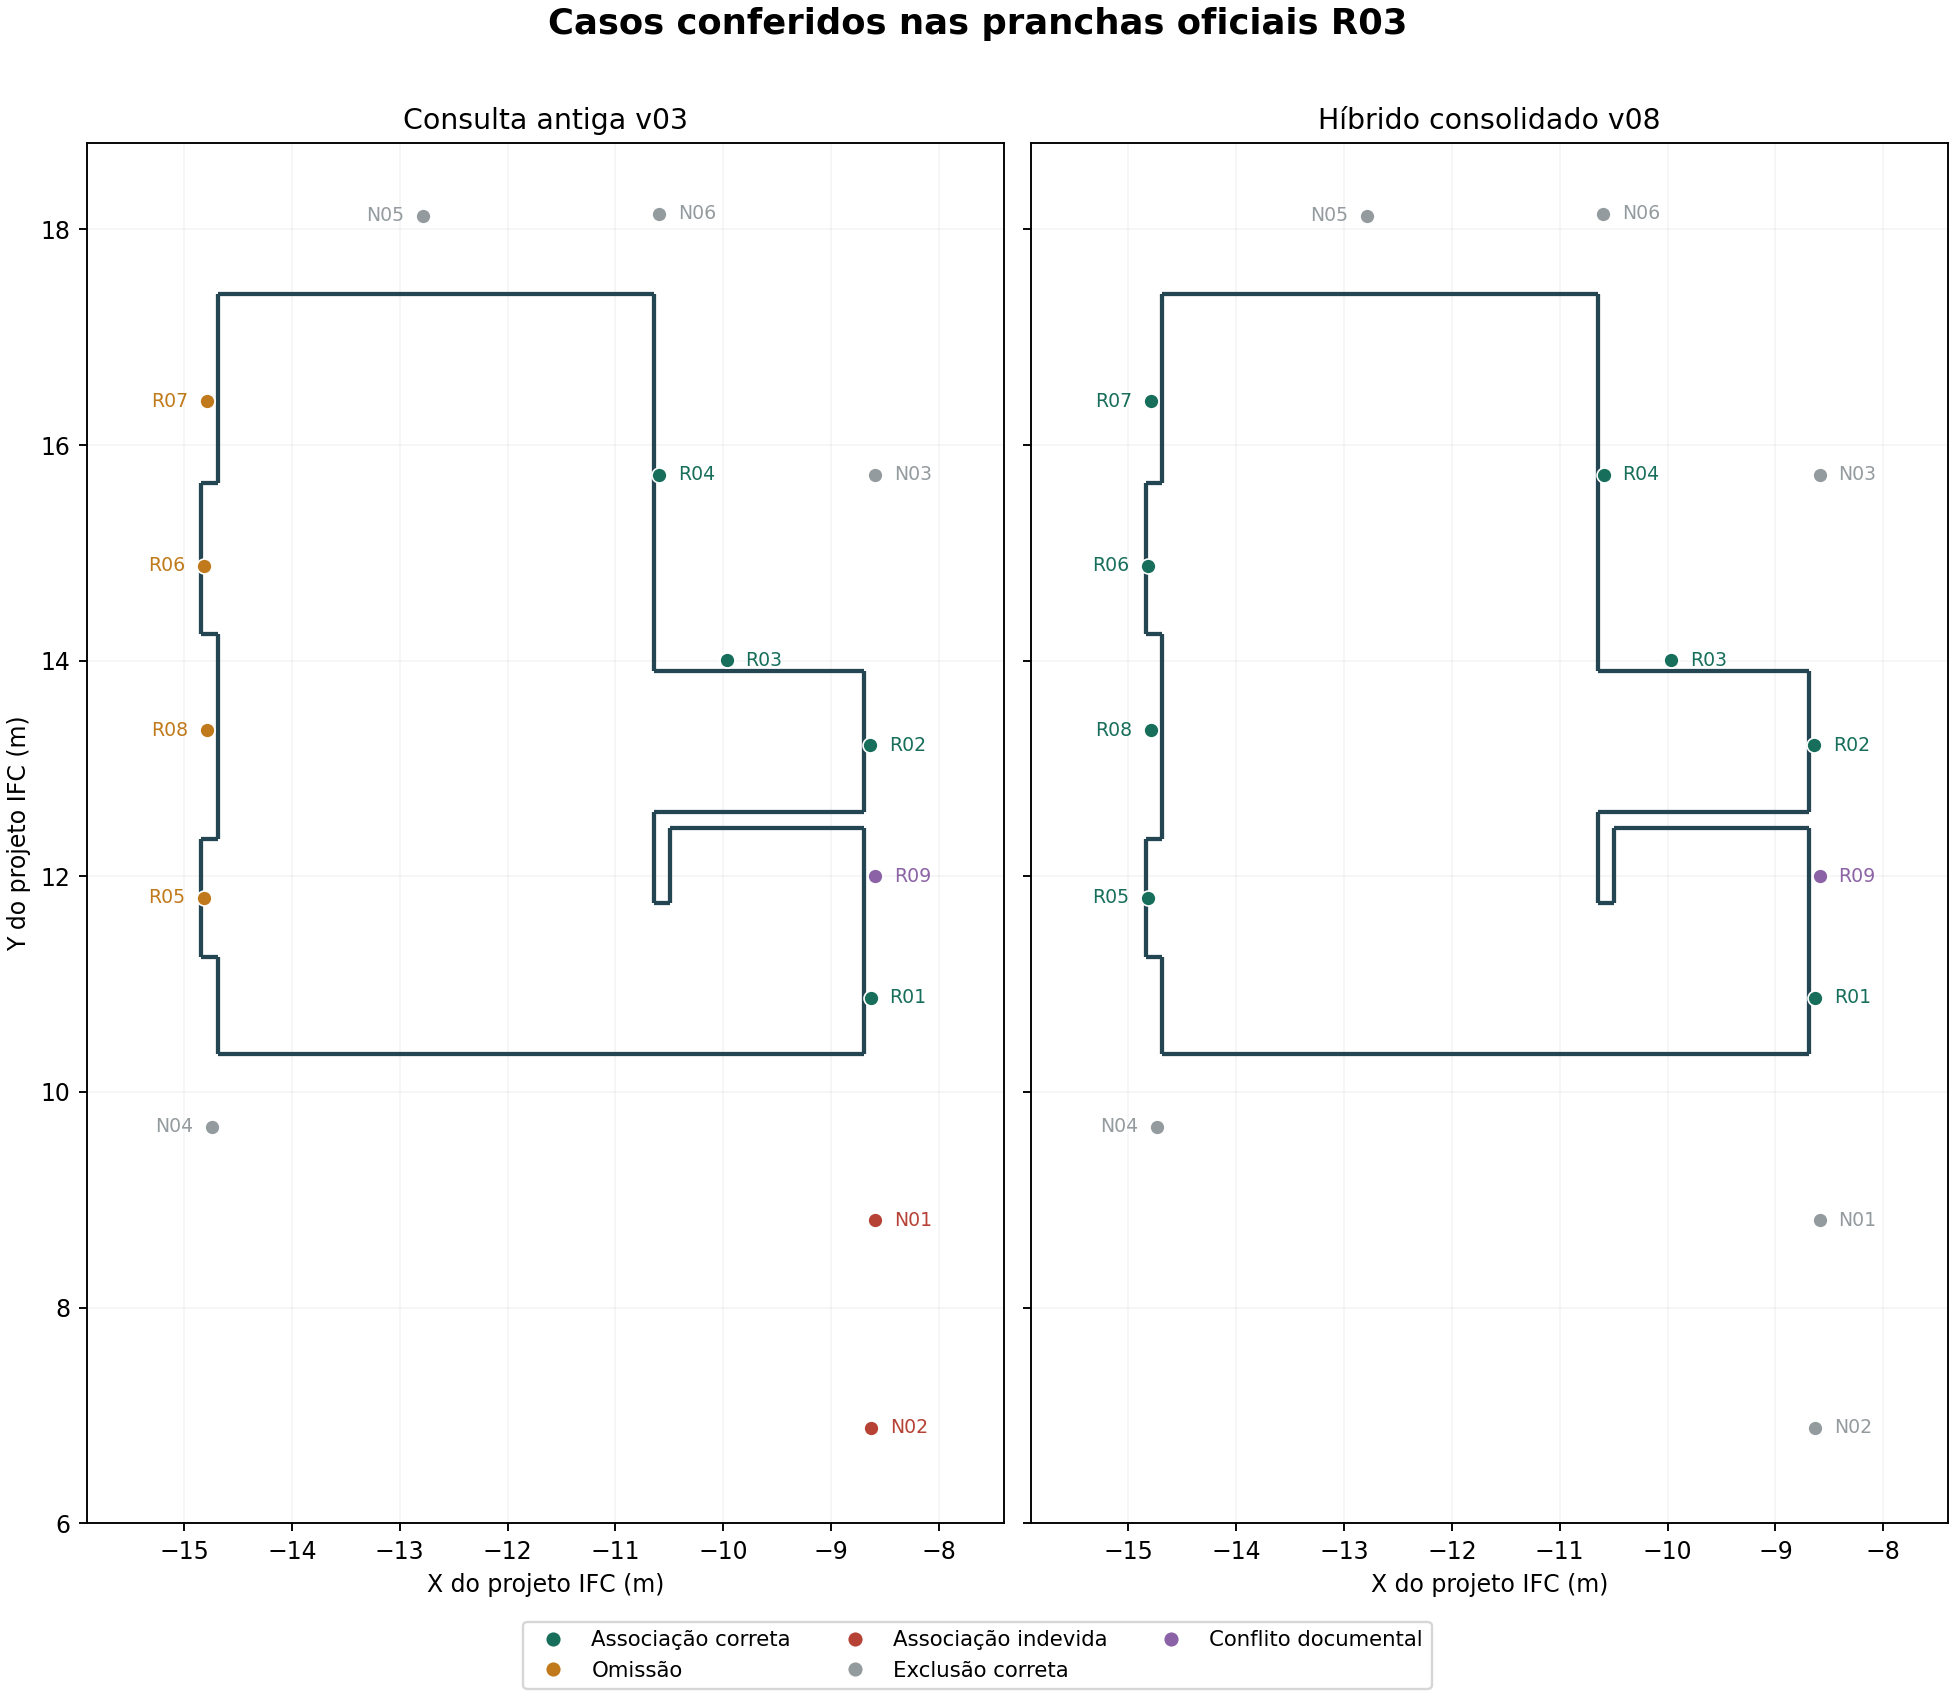

Relatório: C:\Users\prcgu\OneDrive\Documentos\ChatGPT\Artigo da Disciplina BIM\desenvolvimento\consolidacao_hibrido_v01\execucao_notebook\resultados\Relatorio_Consolidacao_Cozinha_v08.html


In [7]:
figuras=SAIDA/'figuras';figuras.mkdir(exist_ok=True)
for p in (RAIZ/'figuras_documentais').glob('*.png'):shutil.copy2(p,figuras/p.name)
from apresentar_consolidacao import run as apresentar
apresentar(SAIDA,REFERENCIAS)
from IPython.display import display,Image
display(Image(filename=str(figuras/'Comparacao_Acertos_Erros_Omissoes.png')))
display(Image(filename=str(figuras/'Mapa_Casos_Conferidos_IFC.png')))
print('Relatório:',SAIDA/'Relatorio_Consolidacao_Cozinha_v08.html')


## 8. Conclusão, limites e integridade

**Ganho demonstrado frente à consulta v03:** quatro janelas recuperadas e duas associações vizinhas removidas. Entre os 14 casos determinados, o núcleo acertou oito associações e seis exclusões, sem omissões ou associações indevidas. A JA-09 permanece fora desses denominadores.

**Comparação com a melhor etapa anterior:** o IFC2SB parcial v04 já produz essas mesmas esquadrias. O híbrido mantém os acertos e acrescenta organização por interface, evidências CGAL, integração ao grafo principal e tratamento separado de elementos internos/componentes. Não atribuímos à combinação um ganho de acurácia que não foi demonstrado frente à v04.

**O que ainda falta:** compatibilizar JA-09 entre pranchas e IFC; obter revisão arquitetônica independente; avaliar outros cômodos; construir referência exaustiva se quisermos medir todas as superfícies, paredes ou demais categorias. As dez alvenarias internas e os componentes recuperados são candidatos com localização/evidência documental, sem certificação integral de função. A regra nova de componentes também precisa ser avaliada em outros exemplos.

**Reprodução e referências:** o pacote registra fontes e hashes, as licenças dos módulos derivados IFC2SB e as pranchas oficiais originais. O conversor e o CGAL anteriores são reutilizados explicitamente; IFC2SB, Kiavarz, inventário, avaliação e integração foram executados nesta revisão. Lilis não foi aplicado novamente ao IFC no núcleo, mas seus controles foram repetidos.

In [8]:
assert sha(IFC)==IFC_SHA
assert all(c['aprovados']==c.get('total',c['aprovados']) for c in [c1,c2,c3,c4])
referencia=json.loads((REFERENCIAS/'Referencia_Documental_Cozinha_R03.json').read_text(encoding='utf8'))
assert all(sha(REFERENCIAS/p['arquivo'])==p['sha256'] for p in referencia['pranchas'])
versoes={'python':sys.version,'numpy':numpy.__version__,'ifcopenshell':ifcopenshell.version,'OCP':OCP.__version__,'shapely':shapely.__version__,'rdflib':rdflib.__version__,'matplotlib':matplotlib.__version__}
verificacao={'snapshot':SNAPSHOT,'ifc_original_preservado':True,'controles_aprovados':59,'resumo_rotina':resultado['resumo'],'metricas_documentais':conferencia['metricas'],'conflitos_documentais':1,'grafoprincipal':integracao,'versoes':versoes,'perfil':'cozinha-FNDE-R03','avaliacao_cega_por_especialista':False,'lilis_executado_no_ifc_nesta_revisao':False}
(SAIDA/'Verificacao_Final_v08.json').write_text(json.dumps(verificacao,ensure_ascii=False,indent=2),encoding='utf8')
print('APROVADO: IFC preservado; 59 controles; previsão e referência separadas; grafo completo reaberto e consultado.')
print('Conferência documental: 8 associações corretas, 6 exclusões corretas; JA-09 pendente.')
print('Resultados:',SAIDA)


APROVADO: IFC preservado; 59 controles; previsão e referência separadas; grafo completo reaberto e consultado.
Conferência documental: 8 associações corretas, 6 exclusões corretas; JA-09 pendente.
Resultados: C:\Users\prcgu\OneDrive\Documentos\ChatGPT\Artigo da Disciplina BIM\desenvolvimento\consolidacao_hibrido_v01\execucao_notebook\resultados
